# Lab 01-02 · Limits and Continuity

Companion to chapter [01-02](../../chapters/01-02-limits-and-continuity.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — Limit tables, and where they break

First $\sin x/x$, then the slope at 0 of $b^x$, $(b^h - 1)/h$, for several bases.

**🔮 Predict:** in double precision, is $(e^h - 1)/h$ at $h = 10^{-12}$ closer to 1 than at $h = 10^{-6}$, or farther?

In [2]:
for x in [0.5, 0.1, 0.01, 0.001]:
    print(f"x = {x:<6}  sin(x)/x = {math.sin(x)/x:.7f}")
print()
print(f"{'h':>8} {'base 2':>10} {'base e':>10} {'base 3':>10}")
for h in [1e-1, 1e-3, 1e-6, 1e-9, 1e-12, 1e-15]:
    row = [(b**h - 1) / h for b in (2, math.e, 3)]
    print(f"{h:>8.0e} " + " ".join(f"{r:10.6f}" for r in row))
print("limits ln 2, 1, ln 3 =", round(math.log(2), 6), 1, round(math.log(3), 6))

x = 0.5     sin(x)/x = 0.9588511
x = 0.1     sin(x)/x = 0.9983342
x = 0.01    sin(x)/x = 0.9999833
x = 0.001   sin(x)/x = 0.9999998

       h     base 2     base e     base 3
   1e-01   0.717735   1.051709   1.161232
   1e-03   0.693387   1.000500   1.099216
   1e-06   0.693147   1.000000   1.098613
   1e-09   0.693147   1.000000   1.098612
   1e-12   0.693223   1.000089   1.098677
   1e-15   0.666134   1.110223   1.110223
limits ln 2, 1, ln 3 = 0.693147 1 1.098612


**Finding e by its defining limit.** Search for the base $b$ whose slope at 0, $\lim (b^h - 1)/h = \ln b$, equals 1. We use a moderate $h$ and bisection (Part 3 explains bisection).

In [3]:
def slope_at_0(b, h=1e-7):
    return (b**h - 1) / h

lo, hi = 2.0, 3.0
for _ in range(40):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if slope_at_0(mid) < 1 else (lo, mid)
print(f"base with slope 1 at x = 0: {mid:.6f}   (e = {math.e:.6f})")
assert abs(mid - math.e) < 1e-5

base with slope 1 at x = 0: 2.718282   (e = 2.718282)


**Total error versus step size.** Plot $\lvert(e^h - 1)/h - 1\rvert$ against $h$ on log–log axes, with the estimate $h/2 + \epsilon/h$ from Problem 01-02.13.

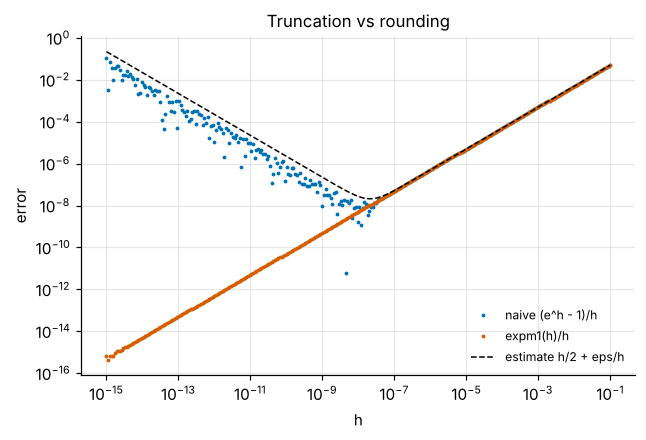

best h ≈ sqrt(2 eps) = 2.1e-08


In [4]:
eps = np.finfo(float).eps
hs = np.logspace(-15, -1, 300)
err = np.abs((np.exp(hs) - 1) / hs - 1)
err_fix = np.abs(np.expm1(hs) / hs - 1)
plt.figure(figsize=(6.5, 4))
plt.loglog(hs, err, ".", ms=3, label="naive (e^h - 1)/h")
plt.loglog(hs, np.maximum(err_fix, 1e-17), ".", ms=3, label="expm1(h)/h")
plt.loglog(hs, hs / 2 + eps / hs, "k--", lw=1, label="estimate h/2 + eps/h")
plt.xlabel("h"); plt.ylabel("error"); plt.legend(fontsize=8); plt.title("Truncation vs rounding")
plt.show()
print(f"best h ≈ sqrt(2 eps) = {math.sqrt(2*eps):.1e}")

## Part 2 — Compounding toward e^r

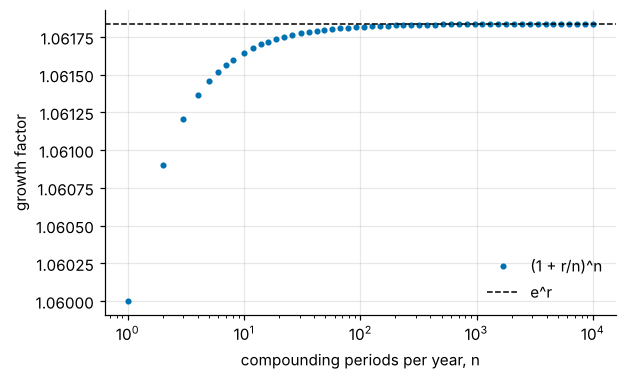

n =    1: 1.060000
n =    4: 1.061364
n =   12: 1.061678
n =  365: 1.061831
limit e^r = 1.061837


In [5]:
r = 0.06
ns = np.unique(np.logspace(0, 4, 60).astype(int))
vals = (1 + r / ns) ** ns
plt.figure(figsize=(6, 3.6))
plt.semilogx(ns, vals, "o", ms=3, label="(1 + r/n)^n")
plt.axhline(math.exp(r), color="k", ls="--", lw=1, label="e^r")
plt.xlabel("compounding periods per year, n"); plt.ylabel("growth factor"); plt.legend(); plt.show()
for n in [1, 4, 12, 365]:
    print(f"n = {n:>4}: {(1 + r/n)**n:.6f}")
print(f"limit e^r = {math.exp(r):.6f}")

## Part 3 — Bisection for a diode operating point

**🔮 Predict:** how many steps to shrink the bracket $[0, 1]$ V below 1 µV?

In [6]:
VT, IS = 0.02585, 1e-14
def g(V):                       # KCL mismatch, amperes (Example 01-02.4)
    return (5 - V) / 1000 - IS * (math.exp(V / VT) - 1)

def bisection(f, a, b, tol):
    fa = f(a)
    assert fa * f(b) < 0, "no sign change: the IVT gives no guarantee"
    steps = 0
    while b - a > tol:
        m = (a + b) / 2
        fm = f(m)
        if fa * fm > 0:
            a, fa = m, fm
        else:
            b = m
        steps += 1
    return (a + b) / 2, steps

V, steps = bisection(g, 0.0, 1.0, 1e-6)
print(f"V = {V:.6f} V after {steps} steps; I = {(5 - V):.4f} mA")
assert steps == 20 and abs(V - 0.69249) < 2e-5

V = 0.692490 V after 20 steps; I = 4.3075 mA


## Part 4 — Asymptotes of a low-pass response

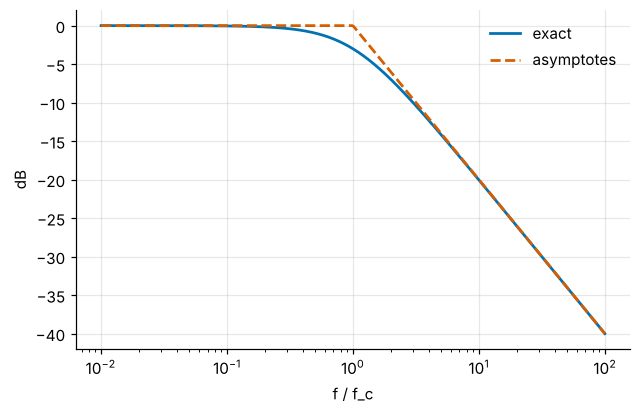

f =    1 f_c: asymptote error = 3.01e+00 dB
f =   10 f_c: asymptote error = 4.32e-02 dB
f =  100 f_c: asymptote error = 4.34e-04 dB
f = 1000 f_c: asymptote error = 4.34e-06 dB


In [7]:
r = np.logspace(-2, 2, 400)                 # f / fc
exact = 20 * np.log10(1 / np.sqrt(1 + r**2))
asym = np.where(r < 1, 0.0, -20 * np.log10(r))
plt.figure(figsize=(6.5, 4))
plt.semilogx(r, exact, label="exact"); plt.semilogx(r, asym, "--", label="asymptotes")
plt.xlabel("f / f_c"); plt.ylabel("dB"); plt.legend(); plt.show()
for k in [1, 10, 100, 1000]:
    e = 20*math.log10(1/math.sqrt(1 + k**2)) - (-20*math.log10(k) if k >= 1 else 0)
    print(f"f = {k:>4} f_c: asymptote error = {abs(e):.2e} dB")

## Part 5 — ngspice confirms the switch limits and the operating point

The two netlists in this folder are checked automatically by `python tools/run_spice.py 01-02` from the repository root. The cell below runs them directly if ngspice is installed.

In [8]:
if shutil.which("ngspice"):
    for net in ["switch_rc.cir", "diode_op.cir"]:
        out = subprocess.run(["ngspice", "-b", net], capture_output=True, text=True).stdout
        lines = [l for l in out.splitlines() if "=" in l and l.split("=")[0].strip() in
                 ("vc_1n", "ic_1u", "vc_1u", "vc_20m", "vd1", "id1", "vd2", "id2")]
        print(net); print("\n".join("   " + l.strip() for l in lines))
else:
    print("ngspice not found; see SETUP.md. Skipping.")

switch_rc.cir
   vc_1n               =  2.500249e-06
   ic_1u               =  4.995005e-04
   vc_1u               =  4.994748e-03
   vc_20m              =  5.000000e+00
diode_op.cir
   vd1 = 0.692543
   id1 = 0.00430746
   vd2 = 0.679696
   id2 = 0.00026203


## Your turn

1. In Part 3, replace bisection by a secant or Newton step and compare step counts. Which fails if you start from $V = 0$?
2. In Part 1, why does the base-2 column reach its limit $\ln 2$ no faster than the base-e column reaches 1?